# Customer Churn Prediction — End-to-End Notebook

**Business problem:** *SwiftNet*, a fictional broadband and mobile company, loses customers every month. The retention
team can offer a discount to customers who are about to leave, but every discount costs money. They want a list of
customers who are **likely to cancel (churn) next month**, so they can spend the discount budget where it helps most.

**What we build:**
1. a classification model that gives each customer a **churn probability**,
2. a **decision threshold** chosen from a simple business cost table (not just the default 0.5),
3. a saved pipeline + `model_info.json` that the Flask API uses for single and batch predictions.

**Methods practised:** classification (Batch 1 Module 08) and model evaluation & optimisation (Module 10):
stratified cross-validation, several metrics, hyperparameter search, learning curves, precision-recall curves and
threshold selection.

**How to run:** start Jupyter from the **project root** (the folder that contains `data/`, `models/` and `backend/`):

```bash
jupyter notebook notebook/Customer_Churn_Prediction.ipynb
```

The whole notebook usually runs in a few minutes on a laptop (the grid search itself takes well under a minute). The first code cell moves to the project root automatically if
you started Jupyter inside `notebook/`.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             confusion_matrix, classification_report, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

# Make paths work whether Jupyter was started in the project root or in notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
print("Working folder:", os.getcwd())
RANDOM_STATE = 42
pd.set_option("display.width", 160)          # show wide tables in full when printed as text
pd.set_option("display.max_columns", 20)

Working folder: /home/claude/Student_Friendly_AI_ML_Course/End_to_End_Projects/ML_Projects/03_Customer_Churn_Prediction


## 1. Load the data and look at it

### Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `customer_id` | Customer identifier (not a feature) | text |
| `tenure_months` | How many months the person has been a customer (0 = joined this month) | integer |
| `contract_type` | Month-to-month, One year or Two year | category |
| `monthly_charges` | Current monthly bill in rupees | number |
| `total_charges` | Total paid so far in rupees — **stored as text**, blank for brand-new customers | text → number |
| `internet_service` | Fiber optic, DSL or No internet | category |
| `tech_support` | Has the tech-support add-on (Yes / No / No internet service) | category |
| `payment_method` | Electronic check, UPI autopay, Credit card (automatic), Bank transfer (automatic) | category |
| `paperless_billing` | Receives bills by e-mail only | Yes / No |
| `num_complaints_6m` | Complaints logged in the last 6 months | integer |
| `avg_data_gb` | Average monthly data use in GB | number |
| `senior_citizen` | 1 if the customer is 60+ | 0 / 1 |
| `city_tier` | Tier 1 (metro), Tier 2, Tier 3 (small town) | category |
| **`churn`** | **Target**: did the customer cancel during the **next** month? | Yes / No |

The data is synthetic (generated by `data/generate_data.py` with a fixed seed) but follows realistic patterns.

In [2]:
df = pd.read_csv("data/telecom_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (5030, 14)


,customer_id,tenure_months,contract_type,monthly_charges,total_charges,internet_service,tech_support,payment_method,paperless_billing,num_complaints_6m,avg_data_gb,senior_citizen,city_tier,churn
0,CUST-02526,23,Month-to-month,1013.0,25867.37,Fiber optic,No,Electronic check,Yes,0,30.8,0,Tier 1,No
1,CUST-02923,10,Month-to-month,232.0,2585.44,No internet,No internet service,UPI autopay,Yes,1,6.5,0,Tier 2,No
2,CUST-00890,23,One year,644.0,13617.27,DSL,No,Bank transfer (automatic),Yes,0,51.9,1,Tier 3,No
3,CUST-00658,6,Month-to-month,581.0,3426.71,DSL,No,UPI autopay,Yes,2,8.5,0,Tier 3,No
4,CUST-04317,5,Two year,199.0,1049.0,No internet,No internet service,Bank transfer (automatic),No,0,3.8,1,Tier 2,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        5030 non-null   str    
 1   tenure_months      5030 non-null   int64  
 2   contract_type      5030 non-null   str    
 3   monthly_charges    5030 non-null   float64
 4   total_charges      5030 non-null   str    
 5   internet_service   5030 non-null   str    
 6   tech_support       5030 non-null   str    
 7   payment_method     5030 non-null   str    
 8   paperless_billing  5030 non-null   str    
 9   num_complaints_6m  5030 non-null   int64  
 10  avg_data_gb        4990 non-null   float64
 11  senior_citizen     5030 non-null   int64  
 12  city_tier          5030 non-null   str    
 13  churn              5030 non-null   str    
dtypes: float64(2), int64(3), str(9)
memory usage: 550.3 KB


Look at the type of `total_charges`: it is **text** (`str`/`object`), not a number, even though it holds money amounts.
That usually means some rows contain something that is not a number. Let's find them.

In [4]:
as_number = pd.to_numeric(df["total_charges"], errors="coerce")   # text that can't be converted becomes NaN
bad = df[as_number.isna()]
print("Rows where total_charges is not a number:", len(bad))
print("Their raw values:", bad["total_charges"].unique().tolist())
print("Their tenure_months:", bad["tenure_months"].unique())

Rows where total_charges is not a number: 132
Their raw values: [' ']
Their tenure_months: [0]


**Found the problem:** every non-numeric `total_charges` is a blank space `' '`, and every one of those customers has
`tenure_months = 0`. They joined this month and **have not been billed yet**, so the correct value is simply **0** —
not "unknown". This is domain knowledge, not a statistic, so it is safe to apply it before splitting the data.

In [5]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

Missing values per column:
customer_id           0
tenure_months         0
contract_type         0
monthly_charges       0
total_charges         0
internet_service      0
tech_support          0
payment_method        0
paperless_billing     0
num_complaints_6m     0
avg_data_gb          40
senior_citizen        0
city_tier             0
churn                 0
dtype: int64

Duplicate rows: 30
Duplicate customer IDs: 30


## 2. Clean the data

1. **Convert `total_charges` to a number** and set the blanks of brand-new customers to 0.
2. **Remove duplicate rows** (the same customer exported twice). If we kept them, the same customer could end up in
   both the training and test sets, which makes the test score look better than it really is.
3. **Missing `avg_data_gb`** values are *not* filled here. The fill value (median) must be learned from training data
   only, so the pipeline does it.
4. Turn the target into **1 = churn, 0 = stays**, because scikit-learn metrics expect the positive class as 1.

In [6]:
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce")
new_customers = df["tenure_months"] == 0
df.loc[new_customers & df["total_charges"].isna(), "total_charges"] = 0.0
print("total_charges is now:", df["total_charges"].dtype, "| still missing:", df["total_charges"].isna().sum())

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows; {len(df)} customers remain")

df["churn"] = (df["churn"] == "Yes").astype(int)
print(f"Churn rate: {df['churn'].mean():.1%}")

total_charges is now: float64 | still missing: 0
Removed 30 duplicate rows; 5000 customers remain
Churn rate: 18.8%


About **1 in 5 customers churn**. The classes are **imbalanced**: a lazy model that always says "stays" would already be
about 81% accurate while finding zero churners. That is why we will not judge models by accuracy.

## 3. Explore: who churns?

The quickest useful view for a classification problem is the **churn rate per group**.

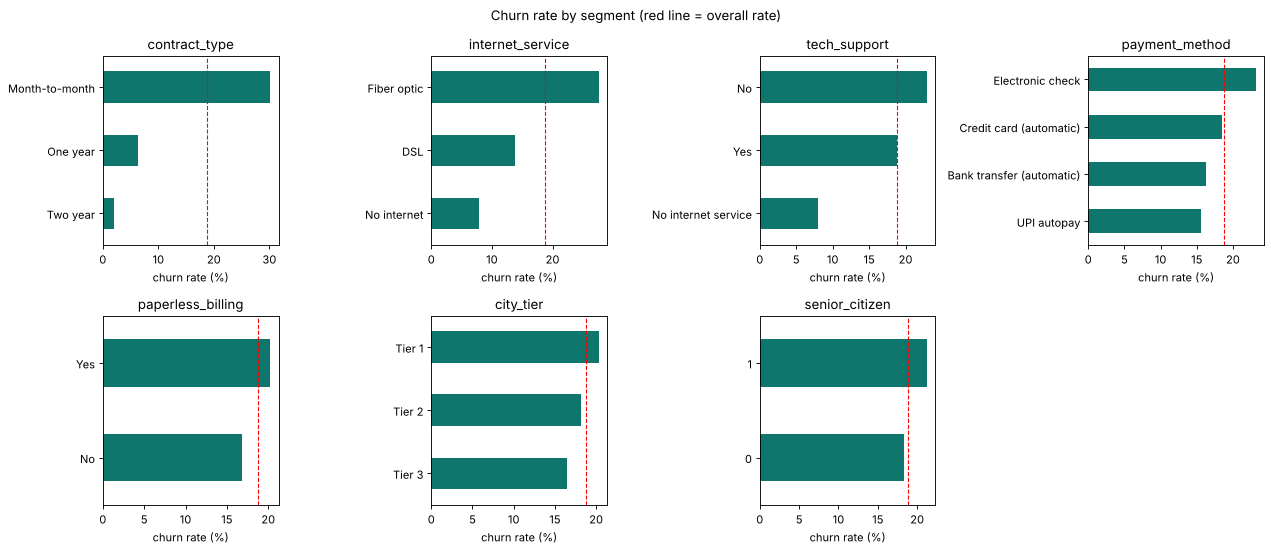

In [7]:
segments = ["contract_type", "internet_service", "tech_support", "payment_method",
            "paperless_billing", "city_tier", "senior_citizen"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), segments):
    rate = df.groupby(col)["churn"].mean().sort_values() * 100
    rate.plot.barh(ax=ax, color="#0f766e")
    ax.axvline(df["churn"].mean() * 100, color="red", linestyle="--", linewidth=1)
    ax.set_title(col); ax.set_xlabel("churn rate (%)"); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Churn rate by segment (red line = overall rate)")
plt.tight_layout()

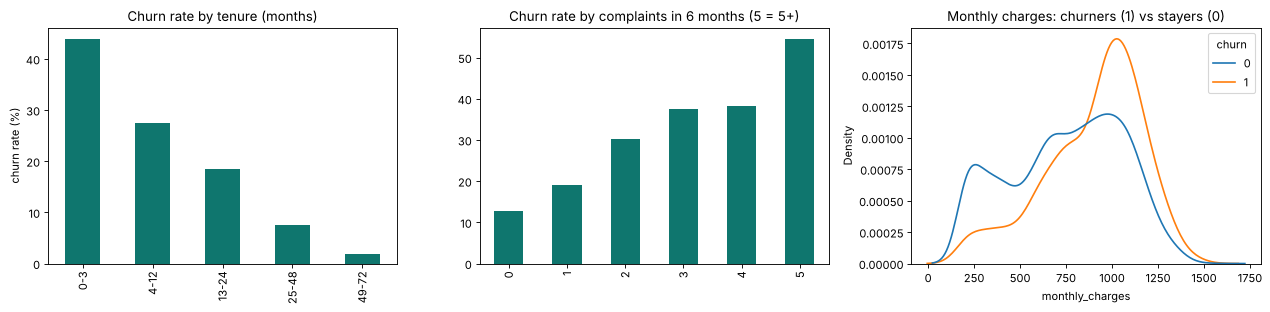

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
tenure_band = pd.cut(df["tenure_months"], [-1, 3, 12, 24, 48, 72], labels=["0-3", "4-12", "13-24", "25-48", "49-72"])
(df.groupby(tenure_band, observed=True)["churn"].mean() * 100).plot.bar(ax=axes[0], color="#0f766e")
axes[0].set_title("Churn rate by tenure (months)"); axes[0].set_ylabel("churn rate (%)"); axes[0].set_xlabel("")
(df.groupby(df["num_complaints_6m"].clip(upper=5))["churn"].mean() * 100).plot.bar(ax=axes[1], color="#0f766e")
axes[1].set_title("Churn rate by complaints in 6 months (5 = 5+)"); axes[1].set_xlabel("")
sns.kdeplot(data=df, x="monthly_charges", hue="churn", common_norm=False, ax=axes[2])
axes[2].set_title("Monthly charges: churners (1) vs stayers (0)")
plt.tight_layout()

In [9]:
# The same story as a table: churn rate and number of customers per contract type
df.groupby("contract_type")["churn"].agg(customers="size", churn_rate="mean").round(3)

,customers,churn_rate
contract_type,,
Month-to-month,2794,0.301
One year,1222,0.064
Two year,984,0.020


**What to notice (these are the patterns the model should learn):**
- **Contract type is the strongest signal**: month-to-month customers churn far more often than two-year customers.
- **New customers** (tenure 0-3 months) churn most; churn falls steadily with tenure.
- **More complaints → more churn.**
- Fibre users, customers **without tech support**, and those paying by **electronic check** churn more.
- Churners have somewhat higher monthly charges.

Several of these are related (new customers are mostly on month-to-month contracts), so a model that looks at all
columns together is more useful than reading one chart at a time.

## 4. Features, target and a stratified split

We keep 20% of customers as a **test set** that we use **only once**, at the very end. All model choices
(which model, which settings, which threshold) are made with cross-validation on the training set.

`stratify=y` keeps the churn rate the same in both parts — important when one class is small.

In [10]:
NUMERIC = ["tenure_months", "monthly_charges", "total_charges", "num_complaints_6m", "avg_data_gb", "senior_citizen"]
CATEGORICAL = ["contract_type", "internet_service", "tech_support", "payment_method", "paperless_billing", "city_tier"]
TARGET = "churn"

X = df[NUMERIC + CATEGORICAL]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, f"churn rate {y_train.mean():.1%}")
print("Test: ", X_test.shape, f"churn rate {y_test.mean():.1%}")

Train: (4000, 12) churn rate 18.8%
Test:  (1000, 12) churn rate 18.8%


## 5. Preprocessing pipeline

- Numeric columns: fill missing values with the training **median**, then standardise (needed for logistic regression;
  harmless for tree models).
- Categorical columns: fill missing with the most frequent value, then one-hot encode. `handle_unknown="ignore"`
  means a category never seen in training will not crash the model.

Because preprocessing lives **inside** the pipeline, cross-validation re-learns it on each training fold — no leakage.

In [11]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL),
])

def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

make_pipe(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

## 6. Baseline and three models with stratified 5-fold cross-validation

**Which metrics, and why?**

| Metric | Question it answers |
|---|---|
| **ROC-AUC** | If I pick one churner and one stayer at random, how often does the model give the churner a higher score? (0.5 = coin flip) |
| **PR-AUC** (average precision) | How good is the ranking *of churners specifically*? Better than ROC-AUC when churners are rare. Baseline = churn rate. |
| **Recall** | Of all customers who really churned, what share did we flag? |
| **Precision** | Of the customers we flagged, what share really churned? (the rest got a discount they didn't need) |
| **F1** | A single balance of precision and recall |

Recall, precision and F1 use the default threshold of 0.5 here; we will choose a better threshold later.

**Stratified K-fold** keeps the ~19% churn rate in every fold, so each fold is a fair mini test.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
           "Recall": "recall", "Precision": "precision", "F1": "f1"}

candidates = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

import warnings
from sklearn.exceptions import UndefinedMetricWarning

rows = []
for name, model in candidates.items():
    start = time.time()
    with warnings.catch_warnings():
        # the baseline never predicts "churn", so precision is 0/0; we know that, so hide the warning
        warnings.simplefilter("ignore", UndefinedMetricWarning)
        scores = cross_validate(make_pipe(model), X_train, y_train, cv=cv, scoring=SCORING)
    row = {"model": name}
    for metric in SCORING:
        row[metric] = scores[f"test_{metric}"].mean()
    row["ROC-AUC std"] = scores["test_ROC-AUC"].std()
    row["seconds"] = time.time() - start
    rows.append(row)

cv_results = pd.DataFrame(rows).set_index("model").round(3)
cv_results

,ROC-AUC,PR-AUC,Recall,Precision,F1,ROC-AUC std,seconds
model,,,,,,,
Baseline (most frequent),0.500,0.188,0.000,0.000,0.000,0.000,0.652
Logistic Regression,0.838,0.537,0.286,0.606,0.387,0.017,1.394
Random Forest,0.824,0.499,0.246,0.597,0.346,0.013,10.063
HistGradientBoosting,0.808,0.465,0.318,0.537,0.397,0.015,73.360


**Reading the table:**
- The **baseline** never predicts churn, so its recall, precision and F1 are 0 and its ROC-AUC is 0.5. Its accuracy
  would look fine (about 81%) — this is exactly why accuracy is misleading here. Its PR-AUC equals the churn rate
  (0.188), the "no-skill" level.
- The `seconds` column is training time for all 5 folds; it depends on your computer, so only compare the rows with
  each other.
- All three real models are far above the baseline. The small standard deviation of ROC-AUC across folds means the
  scores are stable, not luck of one split.
- Recall at the default 0.5 threshold is low for every model: most churners get a probability below 0.5. We will fix
  that with the threshold, not by changing the model.

In [13]:
best_family = cv_results.drop(index="Baseline (most frequent)")["PR-AUC"].idxmax()
print("Best model family by cross-validated PR-AUC:", best_family)

Best model family by cross-validated PR-AUC: Logistic Regression


We pick the family with the best **PR-AUC**, because the retention team works from a ranked list of the
customers most likely to churn, and PR-AUC measures how good that ranking is for the rare class.

**Logistic regression wins** (ROC-AUC 0.838, PR-AUC 0.537) ahead of the random forest and gradient boosting. That
surprises many students, but it is common: when each feature pushes the risk up or down in a fairly simple, additive
way, a simple model is enough, and the flexible tree models mainly add variance. The simpler model is also faster and
easier to explain to the business. Always try a simple model before assuming a complex one is better.

## 7. Tune the best family with `GridSearchCV`

A **small** grid keeps the run time short (each combination is trained 5 times). We tune for PR-AUC as well.
The grid used depends on which family won above.

In [14]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__min_samples_leaf": [2, 5, 10],
        "model__max_features": ["sqrt", 0.5],
    },
    "HistGradientBoosting": {
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [3, None],
        "model__max_leaf_nodes": [15, 31],
    },
}
search = GridSearchCV(make_pipe(candidates[best_family]), param_grids[best_family],
                      cv=cv, scoring="average_precision", n_jobs=-1)
start = time.time()
search.fit(X_train, y_train)
print(f"Grid search took {time.time() - start:.1f} s")
print("Best settings:", search.best_params_)
print(f"Best CV PR-AUC: {search.best_score_:.3f}  (untuned: {cv_results.loc[best_family, 'PR-AUC']:.3f})")

grid_table = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]]
grid_table.sort_values("mean_test_score", ascending=False).round(4).head(8)

Grid search took 12.2 s
Best settings: {'model__C': 0.1, 'model__class_weight': None}
Best CV PR-AUC: 0.537  (untuned: 0.537)


,params,mean_test_score,std_test_score
2,"{'model__C': 0.1, 'model__class_weight': None}",0.5373,0.0342
4,"{'model__C': 1.0, 'model__class_weight': None}",0.5371,0.0355
3,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.5370,0.0326
6,"{'model__C': 10.0, 'model__class_weight': None}",0.5362,0.0357
5,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.5359,0.0336
7,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.5355,0.0332
1,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.5337,0.0319
0,"{'model__C': 0.01, 'model__class_weight': None}",0.5313,0.0322


**Interpretation:** the best setting is `C = 0.1` (slightly stronger regularisation) without class weights, but its
PR-AUC (0.537) is the same as the untuned model to three decimals, and all eight combinations lie within a few
hundredths of each other — smaller than the fold-to-fold standard deviation (about 0.03). So the defaults were already
good and tuning mainly *confirms* that — a common and perfectly fine result. Tuning rarely turns an average model into
a great one; good features and data matter more.

Note that `class_weight="balanced"` did not help PR-AUC: re-weighting the classes shifts the probabilities up, but it
does not change the *ranking* much. We handle the imbalance with the decision threshold instead (section 9).

In [15]:
final_model = search.best_estimator_     # already refit on the whole training set by GridSearchCV
MODEL_NAME = best_family + " (tuned)"

## 8. Learning curve: would more data help?

We train on growing parts of the training set and measure PR-AUC on the training part and with cross-validation.
- Both curves high and close → the model is fine; more data won't change much.
- Training score much higher than validation → **overfitting**; more data or a simpler model may help.
- Both low → **underfitting**; need better features or a more flexible model.

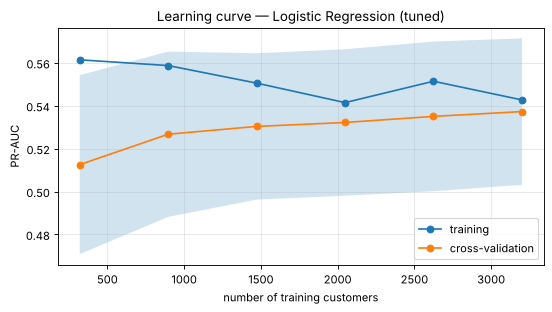

,training PR-AUC,validation PR-AUC
training customers,,
320,0.561,0.513
896,0.559,0.527
1472,0.551,0.530
2048,0.542,0.532
2624,0.551,0.535
3200,0.543,0.537


In [16]:
sizes, train_scores, val_scores = learning_curve(
    final_model, X_train, y_train, cv=cv, scoring="average_precision",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
plt.figure(figsize=(7, 4))
plt.plot(sizes, train_scores.mean(axis=1), "o-", label="training")
plt.plot(sizes, val_scores.mean(axis=1), "o-", label="cross-validation")
plt.fill_between(sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.2)
plt.xlabel("number of training customers"); plt.ylabel("PR-AUC")
plt.title(f"Learning curve — {MODEL_NAME}"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
pd.DataFrame({"training customers": sizes,
              "training PR-AUC": train_scores.mean(axis=1).round(3),
              "validation PR-AUC": val_scores.mean(axis=1).round(3)}).set_index("training customers")

**Reading the curve and the table:** the validation PR-AUC rises only slowly (from about 0.51 with 320 customers to 0.54 with 3,200)
and is flattening, and the training score is only slightly higher (about 0.54 at full size). A small gap and both
curves at the same level means **no overfitting**: the model has learned about as much as these columns allow.
Collecting many more customers of the same kind would give only a small gain; new information (new features) would
help more than more rows.

## 9. Choosing the decision threshold with a business cost table

The model gives a probability. The team still needs a **yes/no decision**: *do we offer this customer a discount?*
The default cut-off 0.5 has no business meaning. Instead we write down what each outcome is worth.

**Business assumptions (agreed with the retention team — change them to match your company):**

| Assumption | Value |
|---|---|
| Cost of the retention offer (discount + agent time) | ₹500 per contacted customer |
| Value of keeping a customer who would have left (≈ 6 months of profit) | ₹4,000 |
| Share of real churners who accept the offer and stay | 30% |

**Profit per customer for each outcome:**

| | Model says **contact** | Model says **don't contact** |
|---|---|---|
| **Customer would churn** (true positive / false negative) | 30% × ₹4,000 − ₹500 = **+₹700** | ₹0 (we lose them, but spend nothing) |
| **Customer would stay** (false positive / true negative) | **−₹500** (discount wasted) | ₹0 |

Simple rule of thumb: contacting someone pays off when *p × 1,200 > 500*, i.e. probability above about **0.42** —
*if* the probabilities are well calibrated. Instead of trusting that, we **measure** the profit for every threshold.

To choose the threshold without touching the test set, we use **out-of-fold** probabilities: `cross_val_predict` gives
every training customer a probability from a model that did *not* see that customer.

In [17]:
OFFER_COST = 500          # rupees per contacted customer
CUSTOMER_VALUE = 4000     # rupees saved when a churner is retained
SUCCESS_RATE = 0.30       # share of contacted churners who stay

def expected_profit(y_true, proba, threshold):
    contact = proba >= threshold
    tp = np.sum(contact & (y_true == 1))
    fp = np.sum(contact & (y_true == 0))
    return tp * (SUCCESS_RATE * CUSTOMER_VALUE - OFFER_COST) - fp * OFFER_COST

oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
y_tr = y_train.to_numpy()
print(f"Out-of-fold ROC-AUC {roc_auc_score(y_tr, oof_proba):.3f}, PR-AUC {average_precision_score(y_tr, oof_proba):.3f}")

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
profit_table = pd.DataFrame({
    "threshold": thresholds,
    "profit": [expected_profit(y_tr, oof_proba, t) for t in thresholds],
    "contacted": [int(np.sum(oof_proba >= t)) for t in thresholds],
    "precision": [precision_score(y_tr, oof_proba >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(y_tr, oof_proba >= t) for t in thresholds],
})
best_row = profit_table.loc[profit_table["profit"].idxmax()]
THRESHOLD = float(best_row["threshold"])
print(f"Best threshold: {THRESHOLD:.2f} -> profit ₹{best_row['profit']:,.0f} on {len(y_tr)} training customers")
profit_table[profit_table["threshold"].isin([0.1, 0.2, 0.3, THRESHOLD, 0.4, 0.5, 0.6])].round(3)

Out-of-fold ROC-AUC 0.837, PR-AUC 0.528
Best threshold: 0.38 -> profit ₹100,700 on 4000 training customers


,threshold,profit,contacted,precision,recall
5,0.10,-264800.0,2212,0.317,0.932
15,0.20,-10400.0,1456,0.411,0.795
25,0.30,85200.0,960,0.491,0.626
33,0.38,100700.0,665,0.543,0.480
35,0.40,95900.0,605,0.549,0.441
45,0.50,78300.0,345,0.606,0.278
55,0.60,44300.0,173,0.630,0.145


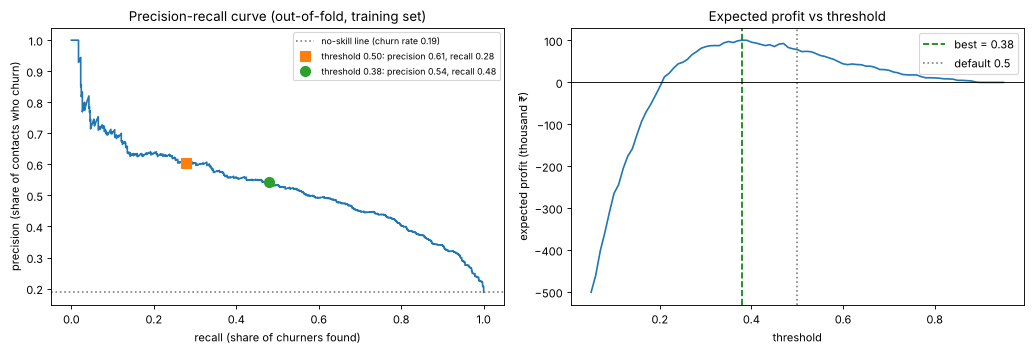

In [18]:
precision, recall, pr_thresholds = precision_recall_curve(y_tr, oof_proba)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(recall, precision)
axes[0].axhline(y_tr.mean(), color="grey", linestyle=":", label=f"no-skill line (churn rate {y_tr.mean():.2f})")
for t, marker in [(0.5, "s"), (THRESHOLD, "o")]:
    p = precision_score(y_tr, oof_proba >= t); r = recall_score(y_tr, oof_proba >= t)
    axes[0].plot(r, p, marker, markersize=9, label=f"threshold {t:.2f}: precision {p:.2f}, recall {r:.2f}")
axes[0].set_xlabel("recall (share of churners found)"); axes[0].set_ylabel("precision (share of contacts who churn)")
axes[0].set_title("Precision-recall curve (out-of-fold, training set)"); axes[0].legend(fontsize=8)

axes[1].plot(profit_table["threshold"], profit_table["profit"] / 1000)
axes[1].axvline(THRESHOLD, color="green", linestyle="--", label=f"best = {THRESHOLD:.2f}")
axes[1].axvline(0.5, color="grey", linestyle=":", label="default 0.5")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("threshold"); axes[1].set_ylabel("expected profit (thousand ₹)")
axes[1].set_title("Expected profit vs threshold"); axes[1].legend()
plt.tight_layout()

**What the plots say:**
- Moving along the PR curve is a trade-off: a lower threshold finds more churners (recall ↑) but more of the contacted
  people would have stayed anyway (precision ↓).
- The profit curve rises, peaks at the chosen threshold, then falls. The chosen threshold is **below 0.5**: because
  saving a churner is worth more than a wasted offer costs, it pays to contact somewhat uncertain customers too.
- At very low thresholds we contact almost everyone and the wasted offers eat the profit.
- The best threshold (0.38) is close to the rule-of-thumb value 0.42 from the cost table, which suggests the
  logistic regression probabilities are reasonably well calibrated.
- The top of the curve is fairly flat: every threshold from 0.30 to 0.50 earns between about ₹78,000 and ₹1,01,000 on
  the 4,000 training customers, while very low thresholds lose money. So the exact value is not critical, but
  "contact almost everyone" is clearly wrong.

## 10. Final evaluation on the test set (done once)

Everything is now fixed: the model, its settings and the threshold. We look at the test set **one time**.

In [19]:
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)
yt = y_test.to_numpy()

test_metrics = {
    "roc_auc": roc_auc_score(yt, test_proba),
    "pr_auc": average_precision_score(yt, test_proba),
    "precision": precision_score(yt, test_pred),
    "recall": recall_score(yt, test_pred),
    "f1": f1_score(yt, test_pred),
}
print(f"Model: {MODEL_NAME}, threshold {THRESHOLD:.2f}")
for k, v in test_metrics.items():
    print(f"  {k:9s} {v:.3f}")
print()
print(classification_report(yt, test_pred, target_names=["stays (0)", "churns (1)"], digits=3))

Model: Logistic Regression (tuned), threshold 0.38
  roc_auc   0.817
  pr_auc    0.501
  precision 0.484
  recall    0.484
  f1        0.484

              precision    recall  f1-score   support

   stays (0)      0.881     0.881     0.881       812
  churns (1)      0.484     0.484     0.484       188

    accuracy                          0.806      1000
   macro avg      0.682     0.682     0.682      1000
weighted avg      0.806     0.806     0.806      1000



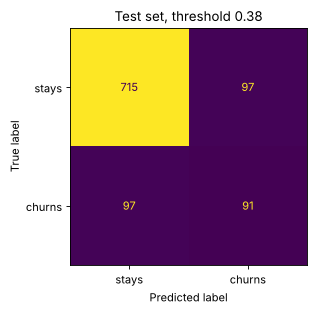

,customers contacted,churners reached,expected profit (₹)
strategy,,,
Contact nobody,0,0,0
Contact everyone,1000,188,-274400
"Model, default threshold 0.5",97,55,17500
"Model, business threshold 0.38",188,91,15200


In [20]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(yt, test_pred), display_labels=["stays", "churns"]).plot(ax=ax, colorbar=False)
ax.set_title(f"Test set, threshold {THRESHOLD:.2f}")
plt.tight_layout()

# What would each strategy earn on the test customers?
strategies = {
    "Contact nobody": 1.01,
    "Contact everyone": 0.0,
    "Model, default threshold 0.5": 0.5,
    f"Model, business threshold {THRESHOLD:.2f}": THRESHOLD,
}
profit_compare = pd.DataFrame([
    {"strategy": s, "customers contacted": int(np.sum(test_proba >= t)),
     "churners reached": int(np.sum((test_proba >= t) & (yt == 1))),
     "expected profit (₹)": int(expected_profit(yt, test_proba, t))}
    for s, t in strategies.items()
]).set_index("strategy")
profit_compare

**Reading the test results (honestly):**
- Test ROC-AUC (0.817) and PR-AUC (0.501) are a little below the cross-validation values (0.838 and 0.537). A gap
  of this size is normal for a test set of 1,000 customers with only 188 churners — the cross-validation scores also
  varied by about ±0.02-0.03 between folds. The model generalises; there is no sign of a serious problem.
- At the business threshold 0.38 the model contacts 188 customers and reaches 91 of the 188 real churners (recall
  0.484) — far more than the default 0.5, which contacts 97 customers and reaches 55. Precision is also 0.484: about half of the
  contacted customers would really have left.
- **Contacting everyone loses a lot of money** (−₹2.7 lakh), because most customers would have stayed anyway. Both
  model-based strategies make a profit. This table is what you show the retention manager.
- **On this test set the default 0.5 earned slightly more (₹17,500) than our chosen 0.38 (₹15,200).** This is not a
  mistake to hide: section 9 showed that the profit curve is fairly flat between 0.30 and 0.50, so on a small sample
  either threshold can win by chance (a difference of ₹2,300 is about five extra offers). We do **not** change the
  threshold after looking at the test set — that would turn the test set into training data. The threshold was
  chosen on 4,000 out-of-fold predictions, which is a larger and more reliable sample, and 0.38 also reaches many more
  churners, which the retention team usually values.
- The profit is an *expected* value under our assumptions (30% accept rate, ₹4,000 value) — if those assumptions
  change, rerun section 9 to pick a new threshold.

## 11. Error analysis: whom do we miss?

In [21]:
test_view = X_test.copy()
test_view["churn"] = yt
test_view["proba"] = test_proba
test_view["outcome"] = np.select(
    [(test_pred == 1) & (yt == 1), (test_pred == 0) & (yt == 1), (test_pred == 1) & (yt == 0)],
    ["caught churner", "missed churner", "false alarm"], default="correct stay")
pd.crosstab(test_view["contract_type"], test_view["outcome"])

outcome,caught churner,correct stay,false alarm,missed churner
contract_type,,,,
Month-to-month,90,318,92,84
One year,1,221,5,8
Two year,0,176,0,5


In [22]:
# The missed churners: what do they look like compared with the churners we caught?
test_view[test_view["churn"] == 1].groupby("outcome")[
    ["tenure_months", "num_complaints_6m", "monthly_charges", "proba"]].mean().round(2)

,tenure_months,num_complaints_6m,monthly_charges,proba
outcome,,,,
caught churner,8.11,1.63,984.41,0.55
missed churner,16.27,0.73,786.30,0.22


**Interpretation:** missed churners look like "safe" customers — compared with the churners we caught they have
longer tenure, fewer complaints, and they are more often on longer contracts. Their churn probability is low, so they
fall under the threshold. Nothing in our columns explains why they leave (perhaps they moved house or a competitor
called them). Catching them would need **new data**, such as recent network outages or competitor offers in their area.

## 12. Which features matter?

**Permutation importance** shuffles one column at a time on the test set and measures how much PR-AUC drops. We only
*look* at the result; the model is not changed any more.

contract_type        0.1227
tenure_months        0.0815
num_complaints_6m    0.0769
monthly_charges      0.0302
payment_method       0.0263
tech_support         0.0126
senior_citizen       0.0091
paperless_billing    0.0083
total_charges        0.0049
internet_service     0.0025
city_tier           -0.0019
avg_data_gb         -0.0030
dtype: float64


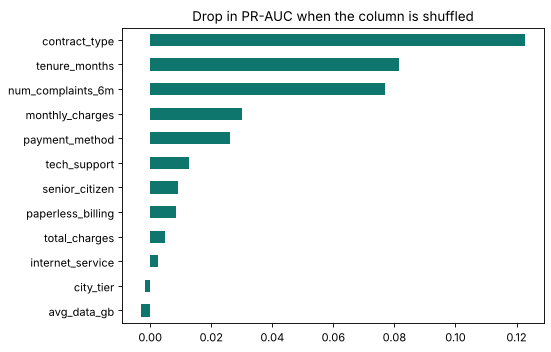

In [23]:
imp = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                             scoring="average_precision", n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
importance.plot.barh(figsize=(7, 4.5), color="#0f766e", title="Drop in PR-AUC when the column is shuffled")
plt.tight_layout()
print(importance.sort_values(ascending=False).round(4))

**Interpretation:** the top three columns are the ones the exploration in section 3 already pointed at — **contract
type**, **tenure** and **complaints** — followed by monthly charges, payment method and tech support.
- `internet_service` scores low even though fibre users churn more. The reason: fibre plans are the expensive ones, so
  `monthly_charges` already carries most of that information. When columns overlap, they **share credit**.
  The same happens with `tenure_months` and `total_charges`.
- `city_tier` and `avg_data_gb` are around zero (tiny negative values are just noise): the model barely uses them.

⚠️ Importance shows what the **model** uses, not what **causes** churn. "Complaints" is a warning sign; the fix is to
solve the customer's problem, not to stop recording complaints.

## 13. New customers and edge cases

In [24]:
new_customers = pd.DataFrame([
    # brand-new month-to-month fibre customer (total_charges 0 because not billed yet)
    {"tenure_months": 0, "contract_type": "Month-to-month", "monthly_charges": 1050, "total_charges": 0,
     "internet_service": "Fiber optic", "tech_support": "No", "payment_method": "Electronic check",
     "paperless_billing": "Yes", "num_complaints_6m": 1, "avg_data_gb": 90, "senior_citizen": 0, "city_tier": "Tier 1"},
    # loyal two-year DSL customer
    {"tenure_months": 60, "contract_type": "Two year", "monthly_charges": 700, "total_charges": 42000,
     "internet_service": "DSL", "tech_support": "Yes", "payment_method": "Bank transfer (automatic)",
     "paperless_billing": "No", "num_complaints_6m": 0, "avg_data_gb": 45, "senior_citizen": 0, "city_tier": "Tier 2"},
    # same loyal customer, but with 4 recent complaints
    {"tenure_months": 60, "contract_type": "Two year", "monthly_charges": 700, "total_charges": 42000,
     "internet_service": "DSL", "tech_support": "Yes", "payment_method": "Bank transfer (automatic)",
     "paperless_billing": "No", "num_complaints_6m": 4, "avg_data_gb": 45, "senior_citizen": 0, "city_tier": "Tier 2"},
    # missing data usage (pipeline fills with the training median) and an unseen payment method (ignored)
    {"tenure_months": 8, "contract_type": "Month-to-month", "monthly_charges": 650, "total_charges": 5200,
     "internet_service": "DSL", "tech_support": "No", "payment_method": "Cash at store",
     "paperless_billing": "No", "num_complaints_6m": 2, "avg_data_gb": np.nan, "senior_citizen": 1, "city_tier": "Tier 3"},
])
new_customers["churn_probability"] = final_model.predict_proba(new_customers[NUMERIC + CATEGORICAL])[:, 1].round(3)
new_customers["contact?"] = np.where(new_customers["churn_probability"] >= THRESHOLD, "Yes - offer discount", "No")
new_customers[["tenure_months", "contract_type", "num_complaints_6m", "payment_method", "churn_probability", "contact?"]]

,tenure_months,contract_type,num_complaints_6m,payment_method,churn_probability,contact?
0,0,Month-to-month,1,Electronic check,0.687,Yes - offer discount
1,60,Two year,0,Bank transfer (automatic),0.002,No
2,60,Two year,4,Bank transfer (automatic),0.012,No
3,8,Month-to-month,2,Cash at store,0.365,No


- The brand-new month-to-month customer gets a high churn probability; the loyal two-year customer a very low one.
- The same loyal customer with 4 complaints gets a higher probability (about 0.01 instead of 0.002) — the model
  reacts to complaints in the right direction, but the two-year contract still keeps the risk very low. In a logistic
  model each complaint multiplies the *odds* of churn, so the change looks small when the starting risk is tiny.
- The 8-month month-to-month customer with 2 complaints gets about 0.37 — just under the threshold, so no discount,
  but the API would put this customer on the "watch list".
- The row with an **unknown payment method** and missing data usage still gets a prediction, because the pipeline fills
  the gap and ignores the unknown category. That is convenient but risky, so **the API rejects unknown categories**
  with a clear message instead of silently guessing.

## 14. Save the pipeline and the information the API needs

- `models/churn_model.joblib` — the **whole pipeline** (preprocessing + tuned model), so the API passes raw values.
- `models/model_info.json` — allowed categories, numeric ranges, the **decision threshold**, the **business
  assumptions** behind it, and the test metrics. The API reads the threshold from here, so changing the business rule
  never requires code changes.

In [25]:
os.makedirs("models", exist_ok=True)
joblib.dump(final_model, "models/churn_model.joblib")

model_info = {
    "model_name": MODEL_NAME,
    "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
    "target": "churn (1 = cancels next month)",
    "numeric_features": NUMERIC,
    "categorical_features": CATEGORICAL,
    "integer_features": ["tenure_months", "num_complaints_6m", "senior_citizen"],
    "categories": {c: sorted(df[c].dropna().unique().tolist()) for c in CATEGORICAL},
    "numeric_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in NUMERIC},
    "threshold": THRESHOLD,
    "business_assumptions": {
        "offer_cost_rupees": OFFER_COST,
        "saved_customer_value_rupees": CUSTOMER_VALUE,
        "offer_success_rate": SUCCESS_RATE,
        "note": "Threshold chosen to maximise expected profit on out-of-fold training predictions.",
    },
    "cv_pr_auc": round(float(search.best_score_), 4),
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "test_churn_rate": round(float(yt.mean()), 4),
    "train_rows": int(len(X_train)),
}
with open("models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)
print(json.dumps({k: model_info[k] for k in ["model_name", "threshold", "test_metrics"]}, indent=2))
print(sorted(os.listdir("models")))

{
  "model_name": "Logistic Regression (tuned)",
  "threshold": 0.38,
  "test_metrics": {
    "roc_auc": 0.8168,
    "pr_auc": 0.5013,
    "precision": 0.484,
    "recall": 0.484,
    "f1": 0.484
  }
}
['churn_model.joblib', 'model_info.json']


In [26]:
# Reload from disk exactly as the API will, and check the probabilities are identical
reloaded = joblib.load("models/churn_model.joblib")
assert np.allclose(reloaded.predict_proba(X_test.head(10)), final_model.predict_proba(X_test.head(10)))
with open("models/model_info.json") as f:
    assert json.load(f)["threshold"] == THRESHOLD
print("Reloaded pipeline gives identical probabilities; threshold stored correctly.")

Reloaded pipeline gives identical probabilities; threshold stored correctly.


## 15. Limitations and possible improvements

- **Synthetic data.** The patterns are realistic but invented. Real churn data is noisier and changes over time
  (new competitors, price changes), so the model must be **monitored and retrained** regularly.
- **Business assumptions drive the threshold.** The ₹500 / ₹4,000 / 30% values are guesses. Run a small A/B test (offer
  vs no offer) to measure the real acceptance rate, then rerun section 9.
- **Probabilities are not perfectly calibrated.** The threshold was chosen by measured profit, which is fine for the
  decision, but the raw probability shown in the app should be read as a *risk score*, not an exact chance.
  `CalibratedClassifierCV` can improve this.
- **The model ranks risk, not "persuadability".** Some high-risk customers would leave whatever we offer; *uplift
  modelling* targets the customers the offer actually changes.
- **Missed churners** look like loyal customers — new data sources (network quality, competitor offers) are needed.
- **Out-of-range inputs** are rejected by the API because tree models cannot extrapolate.
- **Fairness:** `senior_citizen` is used as a feature. Check that offers are not unfairly withheld from or pushed on
  any group before using a model like this for real.

**Next step:** start the Flask API in `backend/` (see the project README). It loads the two files saved above.